# 353: kmerseek lookup of short stretches against measured stretches (ELM and yeast activation tiles)

## Verdict under the fixed rule: NOT RUN

The pass rule needs 100 real short-stretch queries from a work queue. None were supplied,
so the application test (Stage 1) was not run and none of its three numbers exists. No
stand-in queries were made from ELM or the tiles.

| pass-rule condition | threshold | result |
|---|---|---|
| 1. queries with a useful measurement from kmerseek | at least 20 of 100 | not measured |
| 2. median handling time, kmerseek vs comparison | kmerseek at least 50% lower | not measured |
| 3. useful-measurement yield, kmerseek vs comparison | kmerseek no lower | not measured |

Compute: **17.4 CPU-hours** (SLURM TotalCPU over 27 jobs: pilot, 10 development settings,
held-out prep, 14 search chunks, score). Elapsed: **2.4 hours** from the first job's start
to the last job's end (11.2 hours of job wall time summed over jobs that ran side by side);
about 3 hours of wall time from the first download (13:54) to this report, on 2026-10-20.
Budget was two compute-days.

## What Stage 0, the mechanics check, found

Setting picked on the development half and frozen before the held-out half ran:
**mmseqs12, k = 4** (kmerseek 0a22970). Query: windows of the 5,657 held-out records (one,
4 residues long, gives none, so 5,656 give windows). Target: the whole collection of
11,376 records (4,006 ELM motif windows, 7,370 Sanborn 2021 tiles), which kmerseek indexed
as 11,192 targets: it keeps one copy of each k-mer set (point 4).

1. **Substitutions inside a class cost nothing** (contribution a). At E at most 0.1, a
   window's own record is found as often with 3 within-class substitutions as with none:
   0.967 of 15-residue windows, 0.984 of 30-residue windows. This is by construction: the
   substituted query has the same encoded string. Substitutions across classes do cost:
   15-residue windows fall to 0.92 with one and 0.61 with two; 30-residue windows stay at
   0.982 to 0.983. (No baseline was run to say whether BLAST loses more or less.)
2. **Position is right whenever the record is found** (contribution b): found and placed
   (same diagonal as the window's true place) agree in every one of the 203,616 queries
   at all four cut-offs.
3. **A query identical to a record in the reduced alphabet is never shown.** 53-residue
   windows with no cross-class substitution are the whole record in mmseqs12 letters, and
   4 of 22,624 were found: kmerseek skips any target whose k-mer set equals the query's
   (its self-match filter, `compare()` in `src/rust/search.rs`, compares a field the code
   calls `md5sum`, which is a sum of the sketch's k-mer hashes). The 4 found are all one
   record whose sequence holds a U (selenocysteine). With one or two cross-class
   substitutions 0.983 to 0.984 are found. For an evidence lookup this hides the closest
   possible record.
4. **Records with the same k-mer set collapse into one.** kmerseek indexes one copy of each
   k-mer set: 329 records share their mmseqs12 k = 4 k-mer set with another record (305
   share all 53 residues, mostly ELM instances close together on one protein), and the
   index holds 11,192 targets. Of the 93 unchanged 30-residue windows whose own record is
   not found at E at most 0.1 (92 at E at most 10), 92 come from such records: the hit goes
   to the twin record.
5. **The region E-value is calibrated in 0 of 18 strata** (contribution c; strata = window
   length x low-complexity flag x hydrophobic bin; the bins are cut at the 1/3 and 2/3
   quantiles, but ties make them 5,417 / 4,089 / 7,462 windows). On composition shuffles kmerseek
   reports 0.04 to 0.46 of the chance regions the E-value predicts (median 0.13 at E* =
   0.1): the E-value is too large, so it understates significance. On dipeptide shuffles of
   15- and 30-residue windows it reports up to 4.8 times the prediction at E* = 0.1 (median
   2.3 over all strata): too small. Most of that excess lands on records of the window's
   own protein, because a short dipeptide shuffle keeps runs of the original: of 45 such
   regions in a 300-shuffle sample, 12 hit the window's own record, 28 another record of the
   same protein (overlapping tiles), 5 another protein. Counting only other proteins'
   records the dipeptide median is 0.27. The excess is many regions on few shuffles: the
   share of dipeptide shuffles with any region at E at most 0.1 is 0.099, against 0.095
   predicted.
6. Real queries meet other proteins' records at 0.37 to 0.52 regions per query at E at most
   0.1 (range over the 12 substitution levels), where chance alone predicts 0.1. By window
   length it is 0.16 (15 residues), 0.42 (30) and 0.77 (53). These are not called false:
   they include the same ELM motif in related proteins and tiles of related transcription
   factors.

What this means for Stage 1: the lookup itself works (found and placed for 92 to 98% of
15-30 residue windows with up to one cross-class change), but two mechanics need fixing
before an analyst relies on it: identical-in-alphabet records are dropped, and the E-value
cannot be read as a chance-match count for windows this short.

A second reader who had not seen the work tried to disprove each claim; 11 held, 4 held
in part and 1 failed, and the text above is corrected for all of them (section 8).


# 353: does a kmerseek lookup of a short stretch against measured short stretches save evidence-search time?

Kill test, one week, started 2026-10-20. Branch `olgabot/nb353-short-stretch-evidence`.
This cell was committed before any search was run. Its git history is the proof that
the rule did not move after results were seen. Nothing in it is changed later; results go
in the cells below it.

## The question and the decision

An analyst has a 15 to 60 residue stretch of a protein and wants to know whether anyone
has measured something about a similar stretch. Does looking it up with kmerseek against a
small collection of measured short stretches find useful measurements faster than the
tools the analyst already has (BLAST and exact substring search)?

The decision: if the pass rule below holds, kmerseek gets an "evidence lookup for short
stretches" use case in the paper and the docs. If it fails, this use case is dropped and
is not argued for.

## What kmerseek adds here, and nothing else

Every result in this notebook says which of these three it rests on:

- **(a)** matches that survive substitutions inside one alphabet class (an alphabet is the
  way kmerseek groups the 20 amino acids into fewer letters; a substitution inside a class,
  such as I to V in Dayhoff's ILMV class, leaves the encoded letter the same);
- **(b)** the position of the match inside the protein and the region's start and end;
- **(c)** the region E-value, the number of matches this good the search expects by chance.

Anything else (finding identical or near-identical stretches, showing the measurement) the
comparison tools already do.

## Data (frozen under `data/kill_tests/short_stretch/` with dates and SHA-256 sums)

1. **ELM**: every instance ELM marks "true positive" (experimental support), with its
   sequence, coordinates, source protein accession, ELM class and PubMed IDs. The download
   is the one notebook 250 used: ELM instance export format 1.4, downloaded 2026-09-24
   (date in the file header), with protein sequences from the UniProt REST `accessions`
   endpoint on the same day (`scripts/prep_elm_inputs.py` on branch
   `olgabot/elm-motif-transfer`).
2. **Yeast transcription-factor tiles**: Sanborn, A. L., et al. "Simple biochemical
   features underlie transcriptional activation domain diversity and dynamic, fuzzy binding
   to Mediator." *eLife* 10 (2021): e68068. https://doi.org/10.7554/eLife.68068 (resolved
   through PubMed, PMID 33904398). File: `elife-68068-fig1-data1-v3.xlsx` (Figure 1, source
   data 1, "Data from activation assays"), sheet "TF tiles, see Fig 1", downloaded
   2026-10-20 from `https://cdn.elifesciences.org/articles/68068/elife-68068-fig1-data1-v3.xlsx`.
   Every 53-residue tile with its measured activation, weak and inactive tiles included.
3. **Queries for Stage 1**: 100 consecutive real short-stretch queries from a real work
   queue, chosen before either method is run. None were supplied for this run, and none are
   in the repository or project memory. So Stage 1 is **not run**, and no query is copied out
   of ELM or the tile set to stand in. Stage 0 runs alone. The Stage 1 sheets are built
   empty, ready for Olga.

## Stage 0: mechanics

**Collection.** One record per ELM instance and one per tile, each with sequence,
coordinates in the source protein, measurement and reference.

- A tile record is the 53 residues as published, its 0-based start in the TF
  (`position`), the measured activation and Z score, and the paper's DOI. A tile whose
  activation is empty in the file (too few cells were sorted) has no measurement, so it is
  not a record; the count is reported.
- An ELM motif is short (median 6 residues), shorter than any 15-residue query. So an ELM
  record is a 53-residue window of the source protein centred on the motif, the same length
  as a tile, shifted to stay inside the protein; the whole protein if it is shorter than 53;
  the motif itself if it is longer than 53. The record keeps both the window's and the
  motif's coordinates, the ELM class, the methods and the PubMed IDs. An instance whose
  coordinates fall outside the UniProt sequence, or whose protein UniProt did not return, is
  dropped and counted.

**Split.** A record is in the development half when the SHA-256 of its source protein's
accession (isoform suffix removed), read as an integer, is even; otherwise it is held out.
Both halves of a protein's records are therefore on one side.

**One alphabet, one k, picked on the development half and then frozen.** Candidates, all
reduced alphabets (protein20 is left out: it has no classes, so it cannot show (a), and
BLAST already covers it): dayhoff6 at k = 5, 6, 7, 8; sdm12 at k = 4, 5, 6; mmseqs12 at
k = 4, 5, 6. Ten settings. These k are short because a 15-residue query must hold at
least two k-mers between substitutions. kmerseek is the image
`olgabot/kmerseek:2026-10-18-nb344-0a22970` (kmerseek commit 0a22970, the one notebook 344
measured), with extension mismatch penalty 2 and give-up margin 8 (notebook 344's
settings), scaled 1, and every other flag at its default, including the report filters.
The index is the whole collection (both halves) and fits its own Karlin-Altschul
constants (kmerseek's default 200 calibration queries).

- Development queries: 1,000 development records drawn with seed 353. For each, one window
  of 15, 30 and 53 residues at a random offset, and each window at the 12 substitution
  levels below, so 36,000 queries per setting. Substitutions are drawn for each candidate
  alphabet's own classes. Plus 2 dipeptide shuffles (below) of each unchanged window.
- A query is **found** at cut-off E* when kmerseek reports a region against the query's own
  record with `region_evalue` at most E*, whose target interval overlaps the window's true
  interval in that record by at least one residue. It is **placed** (b) when, in addition,
  the region sits on the true diagonal: target start minus query start equals the
  window's offset in the record.
- Score of a setting: the mean, over the 36 combinations of window length and substitution
  level, of the fraction found at E* = 0.1.
- A setting is excluded if, on its development shuffles, the fraction of shuffles with at
  least one region at E at most 0.1 against a record from a different protein is above
  3 x (1 - e^-0.1) = 0.285, three times what a calibrated E-value predicts. If every
  setting is excluded, the one with the smallest ratio of that fraction to 0.095 is kept.
- The highest score wins; a tie goes to the smaller k, then the alphabet with fewer classes.
  The winner is written to `data/kill_tests/short_stretch/frozen_setting.json` and
  committed before any held-out query is searched. No other parameter is searched after
  that.

**Self-retrieval on the held-out half.** Every held-out record gives one window of 15, 30
and 53 residues (a 53-residue record's 53-residue window is the record itself) at a random
offset (seed 353). Each window is searched at these 12 substitution levels, drawn with the
frozen alphabet's classes:

| within-class substitutions | 0 | 1 | 2 | 3 |
|---|---|---|---|---|
| cross-class substitutions 0, 1, 2 | each combination | | | |

A within-class substitution replaces a residue with another residue of the same class (only
residues whose class has two or more members can take one). A cross-class substitution
replaces it with a residue from another class. Positions are distinct and drawn at random.
Recall (found, and placed) is reported for each level at E* = 0.01, 0.1, 1 and 10, next to
the chance-match burden the E-value predicts: E* regions per query. Beside it, the mean
number of regions per query at E at most E* against records of other proteins (these can
be real relatives, such as the same ELM motif in a paralogue, so they are shown, not called
chance).

**Controls on the held-out half.** Each unchanged held-out window gets 20 composition
shuffles (residues reordered at random, `random.shuffle`) and 20 dipeptide shuffles
(every pair of neighbouring residues kept as often as in the window,
`nextflow-runs/shared/decoys.py`, PR 138; a short window often has only a few distinct
dipeptide orders, which is why the task says "where possible"). A shuffle identical to its
window is dropped and counted. Every shuffle goes through the same search, the same report
filters and the same E-value cut-offs as a real query.

- Strata: fraction hydrophobic (A, C, F, I, L, M, V, the residues with positive
  Kyte-Doolittle hydropathy) in thirds, cut at the 1/3 and 2/3 quantiles of the unchanged
  held-out windows, crossed with a low-complexity flag (SEG, `segmasker` with default
  settings, masks at least 15% of the window, notebook 344's cut), crossed with window
  length. A shuffle takes its window's stratum.
- Per stratum, shuffle kind and E* in {0.1, 1, 10}: the observed number of regions at E at
  most E* divided by the number the E-value predicts, (shuffles searched) x E*. Also the
  fraction of shuffles with at least one such region, next to 1 - e^-E*.
- The E-value is **calibrated in a stratum** if that ratio is between 0.5 and 2 at all three
  E* for both shuffle kinds. Otherwise it is too small (ratio above 2: more chance regions
  than predicted) or too large (below 0.5).

Stage 0 has no pass or fail. It shows whether the lookup works mechanically and whether its
E-value can be trusted per stratum, which Stage 1 needs.

## Stage 1: application test (needs the 100 real queries; not run here)

- Comparison workflow: the analyst's current workflow plus (i) local BLAST, `blastp -task
  blastp-short` for queries under 30 residues and standard `blastp` otherwise, against the
  same collection; (ii) exact full-alphabet substring lookup; (iii) the same evidence cards
  (sequence, coordinates, measurement, reference) and the same report format the kmerseek
  workflow shows.
- Self-records and duplicate evidence records are removed before scoring.
- Which workflow is used first is randomised per query.
- A **useful result** is a measurement the analyst had not seen, attached to a matching
  stretch, that the analyst keeps for the current investigation and writes one line saying
  why. A good-looking match with no kept measurement does not count.
- The judge sees a blinded review sheet: method labels are hidden until scoring is done.
- Handling time per query per workflow is recorded with a stopwatch, not estimated.

## Pass rule (fixed now)

Pass only if all three hold:

1. At least 20 of the 100 queries yield a useful measurement with kmerseek.
2. Median handling time with kmerseek is at least 50% lower than with the comparison
   workflow.
3. Useful-measurement yield with kmerseek is no lower than with the comparison workflow.

Fail (drop it) if kmerseek mostly returns records the analyst already knew, saves little
time, or its extra results are stretches of similar composition with no useful measurement.

Without the 100 real queries the verdict is "not run", not pass and not fail.

## Budget

At most two compute-days in total, counting index builds, verification and the report.
CPU-hours (from SLURM accounting) and elapsed hours are reported separately.


## Setup

In [1]:
import gzip
import json
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import pubfig as pf

sys.path.insert(0, str(Path("../scripts/353").resolve()))
from alphabets import CLASSES, HYDROPHOBIC, encode  # noqa: E402

pf.use_style()
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(20)
pl.Config.set_fmt_str_lengths(60)

DATA = Path("../data/kill_tests/short_stretch")
RES = DATA / "results"
FIG = Path("figures/353")
FIG.mkdir(parents=True, exist_ok=True)
E_CUTS = (0.01, 0.1, 1.0, 10.0)
E_SELECT = 0.1  # the cut-off the pre-registration scores recall at
LENGTHS = (15, 30, 53)

frozen = json.loads((DATA / "frozen_setting.json").read_text())
ALPHABET, K = frozen["alphabet"], frozen["k"]
SETTING = f"{ALPHABET}.k{K}"
TOOL = f"kmerseek 0a22970, {ALPHABET} k={K}, extension penalty 2, give-up margin 8"
COLLECTION = "query: windows of held-out records; target: the whole collection (4,006 ELM windows + 7,370 Sanborn 2021 tiles)"

records = pl.read_csv(DATA / "records.tsv", separator="\t", infer_schema_length=0)
rec_by_id = {r["record_id"]: r for r in records.iter_rows(named=True)}
print(f"frozen setting: {SETTING} ({frozen['rule']})")
print(TOOL)

frozen setting: mmseqs12.k4 (highest score among settings not excluded)
kmerseek 0a22970, mmseqs12 k=4, extension penalty 2, give-up margin 8


## 1. The evidence collection

One record per ELM true-positive instance (a 53-residue window centred on the motif) and
one per measured Sanborn 2021 tile. The table is every step of `freeze_counts.tsv`; the
figure shows how the records split between the two halves, and that the tiles keep their
weak and inactive measurements (the activation axis spans the whole screen).

shape: (13, 3)
┌──────────────────────────────────────────────┬──────┬─────────────────────────────────────────┐
│ step                                         ┆ n    ┆ note                                    │
│ ---                                          ┆ ---  ┆ ---                                     │
│ str                                          ┆ i64  ┆ str                                     │
╞══════════════════════════════════════════════╪══════╪═════════════════════════════════════════╡
│ elm: instances in the export                 ┆ 4277 ┆ null                                    │
│ elm: true positive                           ┆ 4047 ┆ other InstanceLogic values dropped      │
│ elm: no UniProt sequence                     ┆ 41   ┆ dropped                                 │
│ elm: coordinates outside the sequence        ┆ 0    ┆ dropped                                 │
│ elm: records                                 ┆ 4006 ┆ null                                    │
│ til

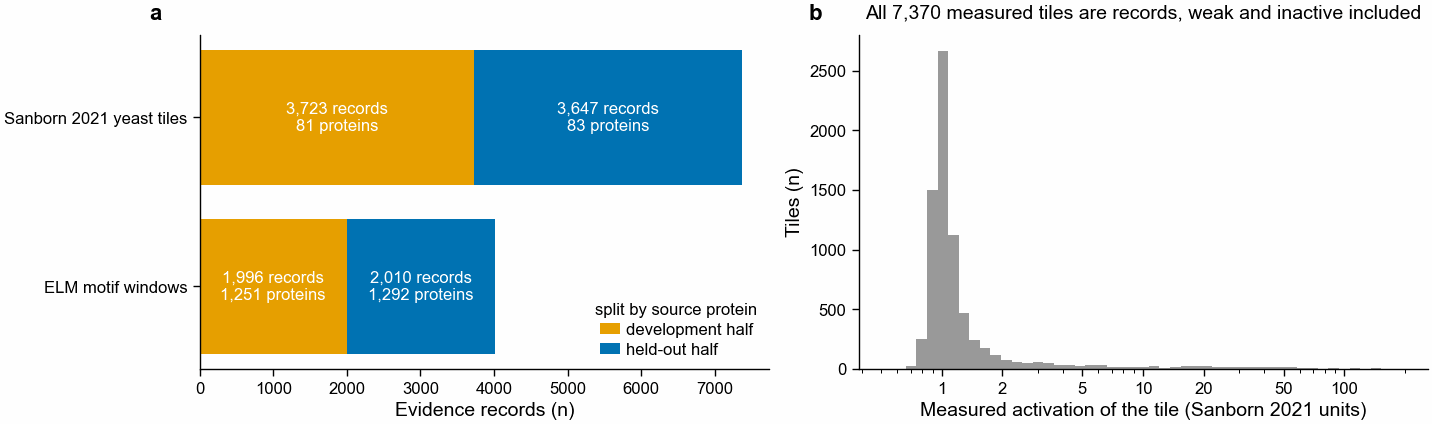

In [2]:
counts = pl.read_csv(DATA / "freeze_counts.tsv", separator="\t")
print(counts)
manifest = pl.read_csv(DATA / "MANIFEST.tsv", separator="\t")
print(manifest.select("file", "download_or_build_date", "sha256"))

by = (
    records.group_by("source", "split")
    .agg(
        pl.len().alias("records"), pl.col("base_accession").n_unique().alias("proteins")
    )
    .sort("source", "split")
)
print(by)
fig, (a, b) = pf.figure(pf.TWO_COLUMN_MM, 55, ncols=2)
src_label = {"elm": "ELM motif windows", "yeast_tile": "Sanborn 2021 yeast tiles"}
split_colour = {"dev": pf.OKABE_ITO["orange"], "held_out": pf.OKABE_ITO["blue"]}
split_label = {"dev": "development half", "held_out": "held-out half"}
y = 0
ticks = []
for src in ("elm", "yeast_tile"):
    left = 0
    for sp in ("dev", "held_out"):
        n = by.filter((pl.col("source") == src) & (pl.col("split") == sp))[
            "records"
        ].item()
        p = by.filter((pl.col("source") == src) & (pl.col("split") == sp))[
            "proteins"
        ].item()
        a.barh(
            y,
            n,
            left=left,
            color=split_colour[sp],
            label=split_label[sp] if src == "elm" else None,
        )
        a.text(
            left + n / 2,
            y,
            f"{n:,} records\n{p:,} proteins",
            ha="center",
            va="center",
            color="white",
            fontsize=6,
        )
        left += n
    ticks.append(src_label[src])
    y += 1
a.set_yticks(range(len(ticks)), ticks)
a.set_xlabel("Evidence records (n)")
a.legend(
    loc="lower right", frameon=False, title="split by source protein", title_fontsize=6
)
act = (
    records.filter(pl.col("source") == "yeast_tile")["activation"]
    .cast(pl.Float64)
    .to_numpy()
)
bins = np.logspace(np.log10(act.min()), np.log10(act.max()), 50)
b.hist(act, bins=bins, color=pf.GREY)
b.set_xscale("log")
b.set_xticks([1, 2, 5, 10, 20, 50, 100], ["1", "2", "5", "10", "20", "50", "100"])
b.set_xlabel("Measured activation of the tile (Sanborn 2021 units)")
b.set_ylabel("Tiles (n)")
b.set_title(
    f"All {len(act):,} measured tiles are records, weak and inactive included",
    fontsize=7,
)
pf.panel_label(a, "a")
pf.panel_label(b, "b")
pf.save(fig, FIG / "353_evidence_collection_elm_sanborn2021")

## 2. One alphabet and k, picked on the development half

The pre-registered rule: the score is the mean, over the 36 combinations of window length
and substitution level, of the fraction of development queries found at E at most 0.1. A
setting is out if more than 3 times the predicted share of its dipeptide shuffles get a
region at E at most 0.1 against another protein's record (dashed line). Higher score is
better; further left is better. The pick is written to `frozen_setting.json`, committed
before the held-out half was searched. Two pairs of marks overlap (dayhoff6 k=5 and k=7;
sdm12 k=4 and k=5): their values differ by less than 0.002 and are in the table.

shape: (10, 10)
┌──────────┬─────┬──────────┬──────────┬──────────┬─────────┬─────────┬─────────┬─────────┬────────┐
│ alphabet ┆ k   ┆ n_classe ┆ n_real_q ┆ score_me ┆ n_shuff ┆ shuffle ┆ shuffle ┆ exclude ┆ picked │
│ ---      ┆ --- ┆ s        ┆ ueries   ┆ an_recal ┆ les     ┆ _rate_e ┆ _rate_o ┆ d       ┆ ---    │
│ str      ┆ i64 ┆ ---      ┆ ---      ┆ l_e0.1   ┆ ---     ┆ 0.1     ┆ ver_pre ┆ ---     ┆ bool   │
│          ┆     ┆ i64      ┆ i64      ┆ ---      ┆ i64     ┆ ---     ┆ dicted  ┆ bool    ┆        │
│          ┆     ┆          ┆          ┆ f64      ┆         ┆ f64     ┆ ---     ┆         ┆        │
│          ┆     ┆          ┆          ┆          ┆         ┆         ┆ f64     ┆         ┆        │
╞══════════╪═════╪══════════╪══════════╪══════════╪═════════╪═════════╪═════════╪═════════╪════════╡
│ dayhoff6 ┆ 5   ┆ 6        ┆ 35988    ┆ 0.668273 ┆ 5600    ┆ 0.01642 ┆ 0.17263 ┆ false   ┆ false  │
│          ┆     ┆          ┆          ┆          ┆         ┆ 9       ┆ 7  

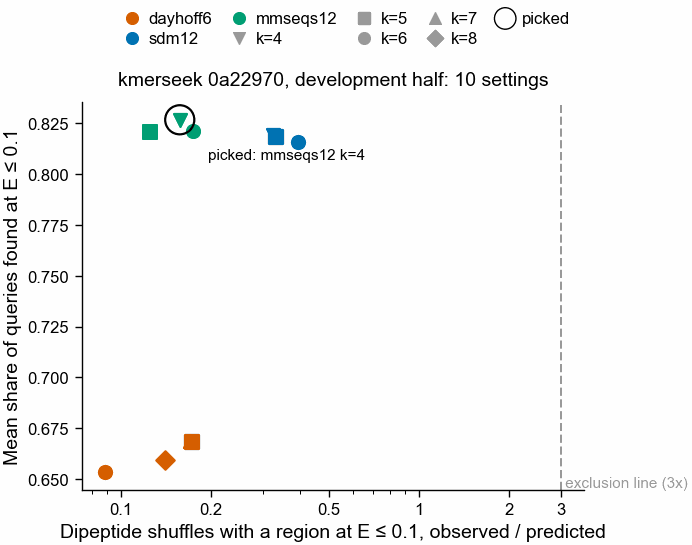

In [3]:
sel = pl.read_csv(DATA / "dev_selection.tsv", separator="\t").sort("alphabet", "k")
print(sel)
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 70)
alpha_colour = {
    "dayhoff6": pf.OKABE_ITO["vermillion"],
    "sdm12": pf.OKABE_ITO["blue"],
    "mmseqs12": pf.OKABE_ITO["bluish_green"],
}
# k is the marker shape (one shape per k, legend above), so no text labels collide.
k_marker = {4: "v", 5: "s", 6: "o", 7: "^", 8: "D"}
for row in sel.iter_rows(named=True):
    c = alpha_colour[row["alphabet"]]
    ax.scatter(
        row["shuffle_rate_over_predicted"],
        row["score_mean_recall_e0.1"],
        s=22,
        marker=k_marker[row["k"]],
        facecolor=c if not row["excluded"] else "white",
        edgecolor=c,
        linewidth=0.8,
        zorder=3,
    )
    if row["picked"]:
        ax.scatter(
            row["shuffle_rate_over_predicted"],
            row["score_mean_recall_e0.1"],
            s=110,
            facecolor="none",
            edgecolor="black",
            linewidth=0.8,
            zorder=4,
        )
        ax.annotate(
            f"picked: {row['alphabet']} k={row['k']}",
            (row["shuffle_rate_over_predicted"], row["score_mean_recall_e0.1"]),
            xytext=(10, -14),
            textcoords="offset points",
            fontsize=5.5,
        )
for name, c in alpha_colour.items():
    ax.scatter([], [], color=c, s=18, label=name)
for kk, m in k_marker.items():
    ax.scatter([], [], color=pf.GREY, marker=m, s=18, label=f"k={kk}")
ax.scatter([], [], facecolor="none", edgecolor="black", s=60, label="picked")
if sel["excluded"].any():
    ax.scatter(
        [], [], facecolor="white", edgecolor="black", s=18, label="excluded (open)"
    )
ax.axvline(3, color=pf.GREY, linestyle="--", linewidth=0.8)
ax.text(
    3,
    ax.get_ylim()[0],
    " exclusion line (3x)",
    fontsize=5.5,
    color=pf.GREY,
    va="bottom",
)
ax.set_xscale("log")
ax.set_xticks([0.1, 0.2, 0.5, 1, 2, 3], ["0.1", "0.2", "0.5", "1", "2", "3"])
ax.set_xlabel("Dipeptide shuffles with a region at E ≤ 0.1, observed / predicted")
ax.set_ylabel("Mean share of queries found at E ≤ 0.1")
fig.legend(loc="outside upper center", ncol=5, frameon=False)
ax.set_title("kmerseek 0a22970, development half: 10 settings", fontsize=7)
pf.save(fig, FIG / "353_setting_choice_development_half")

## 3. Self-retrieval on the held-out half

Each held-out record gives one window of 15, 30 and 53 residues; each window is searched
unchanged and with 1-3 substitutions inside a class (contribution (a)) and 0-2
substitutions across classes. **Found** means a region against the window's own record at
E at most the cut-off, overlapping the window's true place: this rests on (a) and (c).
**Placed** adds the right position inside the record, the same diagonal: (b). Higher is
better. The line for 0 cross-class substitutions is what a reduced alphabet should keep;
cross-class substitutions break k-mers in every alphabet.

203,616 self-retrieval queries on 5,656 held-out records
shape: (36, 12)
┌────────┬────────┬────────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┐
│ length ┆ n_with ┆ n_cros ┆ queri ┆ found ┆ place ┆ found ┆ place ┆ found ┆ place ┆ found ┆ place │
│ ---    ┆ in     ┆ s      ┆ es    ┆ _E0.0 ┆ d_E0. ┆ _E0.1 ┆ d_E0. ┆ _E1   ┆ d_E1  ┆ _E10  ┆ d_E10 │
│ i64    ┆ ---    ┆ ---    ┆ ---   ┆ 1     ┆ 01    ┆ ---   ┆ 1     ┆ ---   ┆ ---   ┆ ---   ┆ ---   │
│        ┆ i64    ┆ i64    ┆ u32   ┆ ---   ┆ ---   ┆ f64   ┆ ---   ┆ f64   ┆ f64   ┆ f64   ┆ f64   │
│        ┆        ┆        ┆       ┆ f64   ┆ f64   ┆       ┆ f64   ┆       ┆       ┆       ┆       │
╞════════╪════════╪════════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╡
│ 15     ┆ 0      ┆ 0      ┆ 5656  ┆ 0.940 ┆ 0.940 ┆ 0.966 ┆ 0.966 ┆ 0.977 ┆ 0.977 ┆ 0.980 ┆ 0.980 │
│        ┆        ┆        ┆       ┆ 948   ┆ 948   ┆ 761   ┆ 761   ┆ 016   ┆ 016   ┆ 552   ┆ 552   │
│ 15     ┆ 1      

queries found but not placed, summed over the four cut-offs: 0
53-residue windows with 0 cross-class substitutions: 22,624 queries, 4 found at E <= 10
30-residue unchanged windows not found at E <= 10: 92 of 5,656; 83 of them come from a record whose 53 residues are identical to another record's
records in the collection sharing their sequence with another record: 305
Chance-match burden the E-value predicts: E* regions per query at E <= E*. Observed against other proteins' records:
shape: (12, 6)
┌──────────┬─────────┬──────────────────────┬───────────────┬───────────────┬──────────────────────┐
│ n_within ┆ n_cross ┆ other-protein        ┆ other-protein ┆ other-protein ┆ other-protein        │
│ ---      ┆ ---     ┆ regions per query,   ┆ regions per   ┆ regions per   ┆ regions per query,   │
│ i64      ┆ i64     ┆ E<=0.01              ┆ query, E<=0.1 ┆ query, E<=1   ┆ E<=10                │
│          ┆         ┆ ---                  ┆ ---           ┆ ---           ┆ ---            

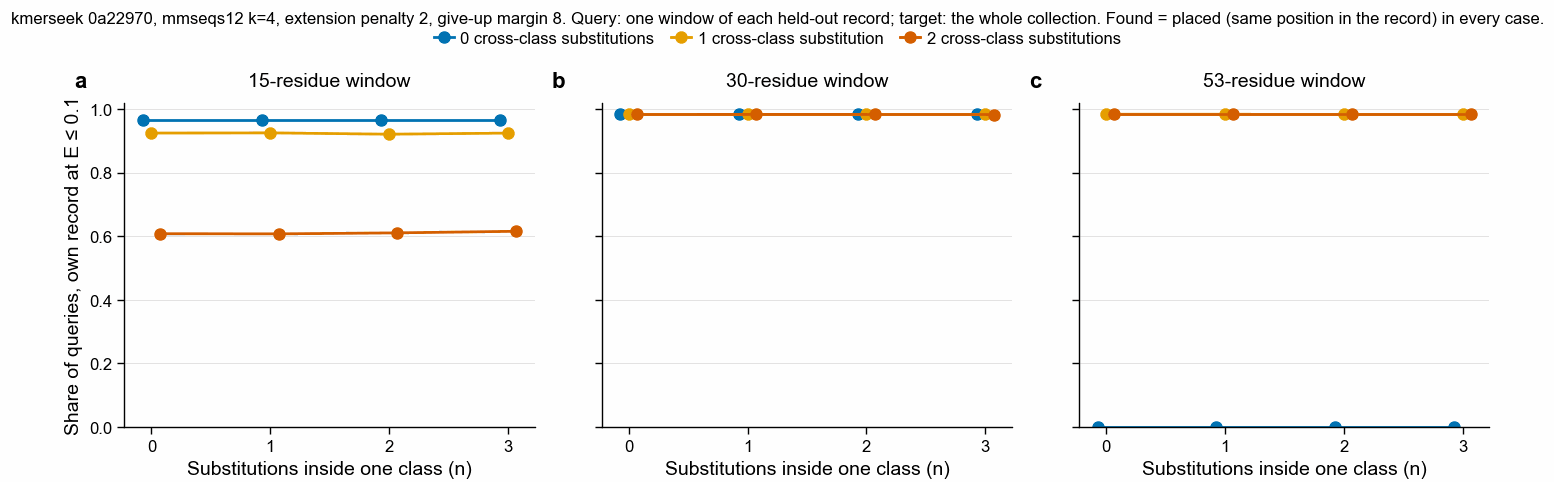

In [4]:
real = pl.read_csv(RES / "held_out" / SETTING / "real_scores.tsv.gz", separator="\t")
print(
    f"{real.height:,} self-retrieval queries on {real['record_id'].n_unique():,} held-out records"
)
agg = []
for e in E_CUTS:
    t = f"{e:g}"
    agg += [
        pl.col(f"found_{t}").mean().alias(f"found_E{t}"),
        pl.col(f"placed_{t}").mean().alias(f"placed_E{t}"),
        pl.col(f"n_other_{t}").mean().alias(f"other_per_query_E{t}"),
    ]
recall = (
    real.group_by("length", "n_within", "n_cross")
    .agg(pl.len().alias("queries"), *agg)
    .sort("length", "n_cross", "n_within")
)
print(
    recall.select(
        "length",
        "n_within",
        "n_cross",
        "queries",
        *[c for c in recall.columns if c.startswith(("found", "placed"))],
    )
)

fig, axs = pf.figure(pf.TWO_COLUMN_MM, 62, ncols=3, sharey=True)
cross_colour = {
    0: pf.OKABE_ITO["blue"],
    1: pf.OKABE_ITO["orange"],
    2: pf.OKABE_ITO["vermillion"],
}
t = f"{E_SELECT:g}"
for ax, L in zip(axs, LENGTHS):
    for c in (0, 1, 2):
        d = recall.filter((pl.col("length") == L) & (pl.col("n_cross") == c)).sort(
            "n_within"
        )
        # Found and placed are equal in every cell (printed above), so one line per
        # cross-class count; a small sideways shift keeps lines that coincide visible.
        assert (d[f"found_E{t}"] == d[f"placed_E{t}"]).all()
        ax.plot(
            d["n_within"] + (c - 1) * 0.07,
            d[f"found_E{t}"],
            color=cross_colour[c],
            marker="o",
            markersize=3.5,
            label=f"{c} cross-class substitution{'s' if c != 1 else ''}",
        )
    ax.set_xticks([0, 1, 2, 3])
    ax.set_xlabel("Substitutions inside one class (n)")
    ax.set_title(f"{L}-residue window", fontsize=7)
    ax.set_ylim(0, 1.02)
    ax.grid(axis="y", color="#dddddd", linewidth=0.3)
axs[0].set_ylabel(f"Share of queries, own record at E ≤ {E_SELECT:g}")
pf.shared_legend(
    fig,
    ncol=3,
    frameon=False,
    title=f"{TOOL}. Query: one window of each held-out record; target: the whole collection. Found = placed (same position in the record) in every case.",
    title_fontsize=6,
)
for ax, letter in zip(axs, "abc"):
    pf.panel_label(ax, letter)
pf.save(
    fig,
    FIG
    / f"353_recall_vs_substitutions_heldout_{SETTING.replace(".", "_")}_elm_sanborn2021",
)

found_not_placed = sum(
    (real[f"found_{e:g}"] & ~real[f"placed_{e:g}"]).sum() for e in E_CUTS
)
print(
    f"queries found but not placed, summed over the four cut-offs: {found_not_placed}"
)

# Why the unchanged 53-residue window is not found: it is the whole record, so its k-mer
# set equals the record's, and kmerseek skips a target whose sketch MD5 equals the query's
# (src/rust/search.rs, compare(), at 0a22970). Within-class substitutions do not change
# the k-mer set either, so 53-residue queries with 0 cross-class substitutions are dropped.
r53 = real.filter((pl.col("length") == 53) & (pl.col("n_cross") == 0))
print(
    f"53-residue windows with 0 cross-class substitutions: {r53.height:,} queries, {r53['found_10'].sum()} found at E <= 10"
)

# The 30-residue unchanged windows that are missed: is their record's sequence shared by another record?
dup = records.group_by("sequence").agg(pl.len().alias("records_with_this_sequence"))
miss30 = (
    real.filter(
        (pl.col("length") == 30)
        & (pl.col("n_within") == 0)
        & (pl.col("n_cross") == 0)
        & ~pl.col("found_10")
    )
    .join(records.select("record_id", "sequence", "source"), on="record_id")
    .join(dup, on="sequence")
)
print(
    f"30-residue unchanged windows not found at E <= 10: {miss30.height} of {real.filter((pl.col('length') == 30) & (pl.col('n_within') == 0) & (pl.col('n_cross') == 0)).height:,}; "
    f"{(miss30['records_with_this_sequence'] > 1).sum()} of them come from a record whose 53 residues are identical to another record's"
)
print(
    f"records in the collection sharing their sequence with another record: {records.join(dup, on='sequence').filter(pl.col('records_with_this_sequence') > 1).height}"
)

burden = (
    real.group_by("n_within", "n_cross")
    .agg(
        *[
            pl.col(f"n_other_{e:g}")
            .mean()
            .alias(f"other-protein regions per query, E<={e:g}")
            for e in E_CUTS
        ]
    )
    .sort("n_cross", "n_within")
)
print(
    "Chance-match burden the E-value predicts: E* regions per query at E <= E*. Observed against other proteins' records:"
)
print(burden)
burden_len = (
    real.group_by("length")
    .agg(
        pl.col(f"n_other_{E_SELECT:g}")
        .mean()
        .alias("other-protein regions per query, E<=0.1")
    )
    .sort("length")
)
print("the same, by window length (all substitution levels pooled):")
print(burden_len)


# kmerseek indexes one copy of each k-mer set ("Skipped ... sequences whose signature key was
# already indexed" in the index log), so records with the same mmseqs12 k=4 k-mer set collapse.
def kmer_set(seq):
    enc = encode(seq, ALPHABET)
    return frozenset(
        enc[i : i + K] for i in range(len(enc) - K + 1) if "." not in enc[i : i + K]
    )


kset = {rid: kmer_set(r["sequence"]) for rid, r in rec_by_id.items()}
from collections import Counter

kcount = Counter(kset.values())
print(
    f"records sharing their {ALPHABET} k={K} k-mer set with another record: {sum(kcount[v] > 1 for v in kset.values())}; "
    f"distinct k-mer sets: {len(kcount):,} of {len(kset):,} records"
)
miss30b = real.filter(
    (pl.col("length") == 30)
    & (pl.col("n_within") == 0)
    & (pl.col("n_cross") == 0)
    & ~pl.col(f"found_{E_SELECT:g}")
)
print(
    f"30-residue unchanged windows not found at E <= {E_SELECT:g}: {miss30b.height}; "
    f"{sum(kcount[kset[r]] > 1 for r in miss30b['record_id'])} of them from a record whose k-mer set another record shares"
)

**How to read it.** Each line is one number of cross-class substitutions; along the
x axis only substitutions inside a class are added. Flat lines mean contribution (a) holds:
those substitutions cost nothing, because the query's mmseqs12 string does not change.
The blue line at 0 in panel c is not a recall failure of the search: an unchanged
53-residue window is the whole record, and kmerseek drops a target whose k-mer set equals
the query's (the self-match filter in `compare()`, kmerseek `src/rust/search.rs` at
0a22970). The decision it informs: before Stage 1, the self-match filter has to be
switchable off for evidence lookups, or a query identical in the alphabet to a record will
never see that record.

## 4. Shuffled controls: is the E-value calibrated per stratum?

Every unchanged held-out window was shuffled 20 times keeping its composition and 20 times
keeping its adjacent-residue pairs where possible, and each shuffle went through the same
search, report filters and E-value cut-offs. Any region a shuffle gets is a chance match.
If the E-value is right, shuffles searched x E* regions turn up at E at most E*, so the
ratio observed / predicted is 1 (grey band: 0.5 to 2, the pre-registered tolerance).
Above 2 the E-value is too small (it calls chance matches significant); below 0.5 it is
too large. Strata: share of hydrophobic residues (A, C, F, I, L, M, V) in thirds, SEG
low-complexity flag, window length.

hydrophobic-share cut points (1/3 and 2/3 quantiles of 16,968 unchanged windows): 0.267, 0.333
windows by SEG flag: shape: (6, 3)
┌────────┬────────────────┬──────┐
│ length ┆ low_complexity ┆ len  │
│ ---    ┆ ---            ┆ ---  │
│ i64    ┆ bool           ┆ u32  │
╞════════╪════════════════╪══════╡
│ 15     ┆ false          ┆ 5242 │
│ 15     ┆ true           ┆ 414  │
│ 30     ┆ false          ┆ 4566 │
│ 30     ┆ true           ┆ 1090 │
│ 53     ┆ false          ┆ 3845 │
│ 53     ┆ true           ┆ 1811 │
└────────┴────────────────┴──────┘
shape: (108, 11)
┌─────────┬────────┬─────────┬────────┬──────┬────────┬────────┬────────┬────────┬────────┬────────┐
│ kind    ┆ length ┆ hydroph ┆ low_co ┆ E*   ┆ shuffl ┆ observ ┆ predic ┆ ratio  ┆ share_ ┆ predic │
│ ---     ┆ ---    ┆ obic    ┆ mplexi ┆ ---  ┆ es     ┆ ed_reg ┆ ted_re ┆ ---    ┆ with_h ┆ ted_sh │
│ str     ┆ i64    ┆ ---     ┆ ty     ┆ f64  ┆ ---    ┆ ions   ┆ gions  ┆ f64    ┆ it     ┆ are    │
│         ┆        ┆ str     

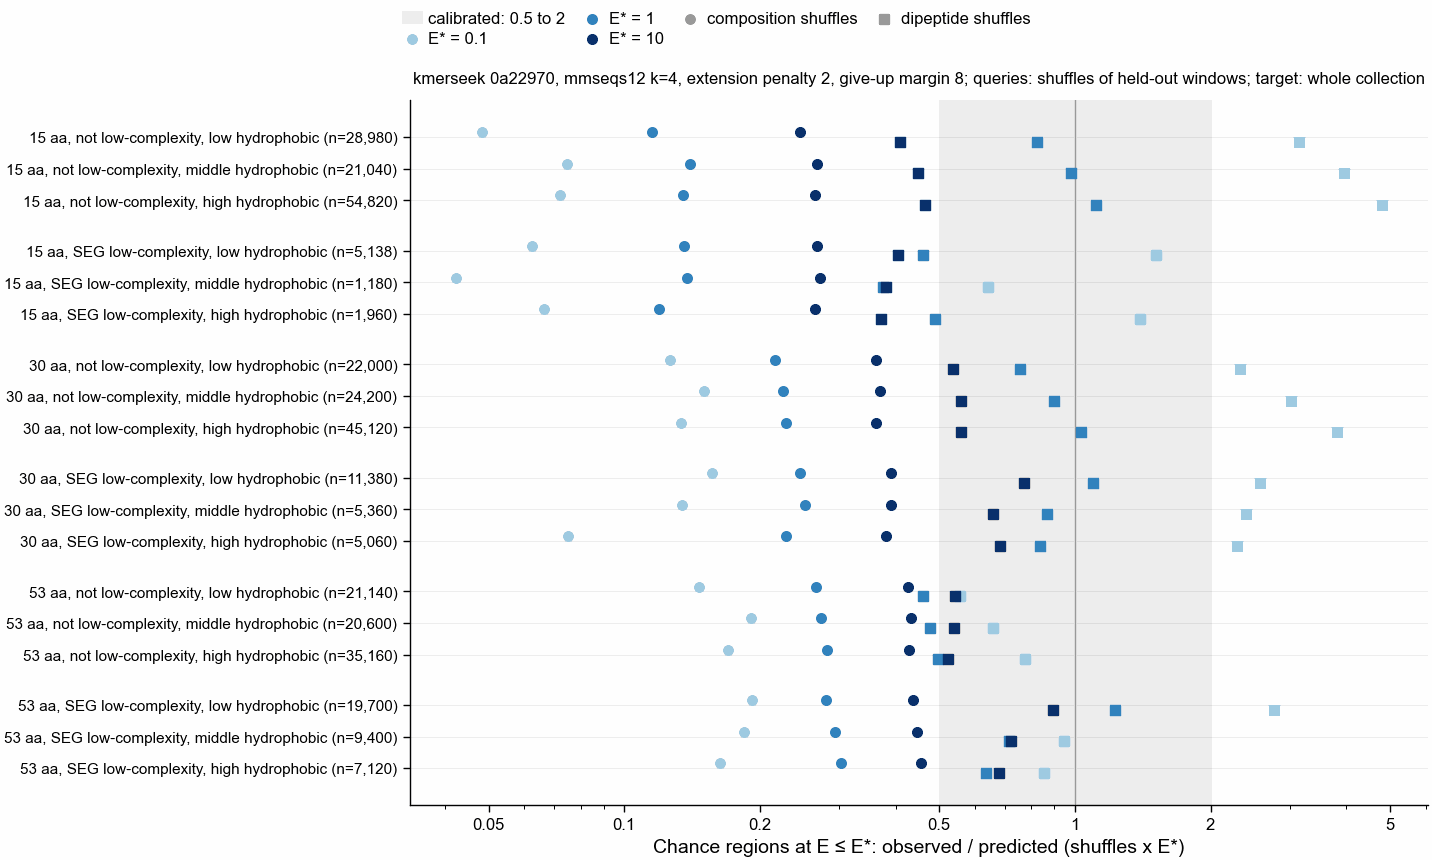

In [5]:
shuf = pl.read_csv(RES / "held_out" / SETTING / "shuffle_scores.tsv.gz", separator="\t")
seg = pl.read_csv(RES / "held_out" / SETTING / "seg_flags.tsv.gz", separator="\t")
windows = real.filter((pl.col("n_within") == 0) & (pl.col("n_cross") == 0)).select(
    "record_id", "length", "frac_hydrophobic"
)
q1, q2 = windows["frac_hydrophobic"].quantile(1 / 3, "linear"), windows[
    "frac_hydrophobic"
].quantile(2 / 3, "linear")
print(
    f"hydrophobic-share cut points (1/3 and 2/3 quantiles of {windows.height:,} unchanged windows): {q1:.3f}, {q2:.3f}"
)


def hydro_bin(col):
    return (
        pl.when(col < q1)
        .then(pl.lit("low"))
        .when(col < q2)
        .then(pl.lit("middle"))
        .otherwise(pl.lit("high"))
    )


shuf = shuf.join(
    seg.select("record_id", "length", "low_complexity"),
    on=["record_id", "length"],
    how="left",
).with_columns(hydro_bin(pl.col("frac_hydrophobic")).alias("hydrophobic"))
assert shuf["low_complexity"].null_count() == 0
counts_lc = (
    windows.join(seg, on=["record_id", "length"])
    .group_by("length", "low_complexity")
    .len()
    .sort("length", "low_complexity")
)
print("windows by SEG flag:", counts_lc)
CAL_CUTS = (0.1, 1.0, 10.0)
rows = []
for (kind, L, h, lc), g in shuf.group_by(
    "kind", "length", "hydrophobic", "low_complexity"
):
    n = g.height
    for e in CAL_CUTS:
        obs = g[f"n_regions_{e:g}"].sum()
        rows.append(
            {
                "kind": kind,
                "length": L,
                "hydrophobic": h,
                "low_complexity": lc,
                "E*": e,
                "shuffles": n,
                "observed_regions": obs,
                "predicted_regions": n * e,
                "ratio": obs / (n * e),
                "share_with_hit": (g[f"n_regions_{e:g}"] > 0).mean(),
                "predicted_share": 1 - math.exp(-e),
            }
        )
cal = pl.DataFrame(rows).sort("length", "low_complexity", "hydrophobic", "kind", "E*")
stratum = ["length", "hydrophobic", "low_complexity"]
verdict = (
    cal.group_by(stratum)
    .agg(
        ((pl.col("ratio") >= 0.5) & (pl.col("ratio") <= 2)).all().alias("calibrated"),
        pl.col("ratio").min().alias("min_ratio"),
        pl.col("ratio").max().alias("max_ratio"),
        pl.col("shuffles").max().alias("shuffles_per_kind"),
    )
    .sort(stratum)
)
print(
    cal.select(
        "kind",
        *stratum,
        "E*",
        "shuffles",
        "observed_regions",
        "predicted_regions",
        "ratio",
        "share_with_hit",
        "predicted_share",
    )
)
print(verdict)
print(f"strata calibrated: {verdict['calibrated'].sum()} of {verdict.height}")
print(
    "unchanged windows per hydrophobic bin (the cut points tie many windows, so the bins are not equal thirds):"
)
print(
    windows.with_columns(hydro_bin(pl.col("frac_hydrophobic")).alias("hydrophobic"))
    .group_by("hydrophobic")
    .len()
    .sort("hydrophobic")
)
pooled = shuf.filter(pl.col("kind") == "dipeptide")
print(
    f"dipeptide shuffles with any region at E <= 0.1, pooled: {(pooled['n_regions_0.1'] > 0).mean():.3f} (calibrated prediction {1 - math.exp(-0.1):.3f})"
)
# Where the dipeptide regions at E <= 0.1 land, in the 300 shuffles score.py kept every region for.
exs = pl.read_csv(
    RES / "held_out" / SETTING / "examples.tsv.gz",
    separator="\t",
    infer_schema_length=10000,
    schema_overrides={"query_name": pl.String, "target_name": pl.String},
)
exs = exs.filter((pl.col("kind") == "dipeptide") & (pl.col("region_evalue") <= 0.1))
print(
    "dipeptide-shuffle regions at E <= 0.1 in the 300-shuffle sample:",
    {
        "own record": int(exs["own_record"].sum()),
        "other record, same protein": int(
            (~exs["own_record"] & ~exs["other_protein"]).sum()
        ),
        "other protein": int(exs["other_protein"].sum()),
    },
)
by_kind = (
    cal.group_by("kind", "E*")
    .agg(
        pl.col("ratio").min().alias("min_ratio"),
        pl.col("ratio").median().alias("median_ratio"),
        pl.col("ratio").max().alias("max_ratio"),
    )
    .sort("kind", "E*")
)
print("observed / predicted across the 18 strata, by shuffle kind and cut-off:")
print(by_kind)

# Not the pre-registered count: the same ratio counting only regions against records of a
# protein other than the window's own. A dipeptide shuffle of a short window keeps runs of
# the window, so some of its regions land back on its own record.
other_rows = []
for (kind, e), g in [
    ((k, e), shuf.filter(pl.col("kind") == k))
    for k in ("composition", "dipeptide")
    for e in CAL_CUTS
]:
    per = g.group_by(stratum).agg(
        (pl.col(f"n_other_{e:g}").sum() / (pl.len() * e)).alias(
            "ratio_other_protein_only"
        )
    )
    other_rows.append(
        per.with_columns(pl.lit(kind).alias("kind"), pl.lit(e).alias("E*"))
    )
other = (
    pl.concat(other_rows)
    .group_by("kind", "E*")
    .agg(
        pl.col("ratio_other_protein_only").min().alias("min"),
        pl.col("ratio_other_protein_only").median().alias("median"),
        pl.col("ratio_other_protein_only").max().alias("max"),
    )
    .sort("kind", "E*")
)
print(
    "Not the rule: observed / predicted counting only regions on other proteins' records:"
)
print(other)

hord = {"low": 0, "middle": 1, "high": 2}
labels, ypos = [], {}
y = 0
for L in LENGTHS:
    for lc in (False, True):
        for h in ("low", "middle", "high"):
            if verdict.filter(
                (pl.col("length") == L)
                & (pl.col("low_complexity") == lc)
                & (pl.col("hydrophobic") == h)
            ).height:
                ypos[(L, lc, h)] = y
                n = cal.filter(
                    (pl.col("length") == L)
                    & (pl.col("low_complexity") == lc)
                    & (pl.col("hydrophobic") == h)
                )["shuffles"].max()
                labels.append(
                    f"{L} aa, {'SEG low-complexity' if lc else 'not low-complexity'}, {h} hydrophobic (n={n:,})"
                )
                y += 1
        y += 0.6
fig, ax = pf.figure(pf.TWO_COLUMN_MM, 110)
ax.axvspan(0.5, 2, color="#eeeeee", zorder=0, label="calibrated: 0.5 to 2")
ax.axvline(1, color=pf.GREY, linewidth=0.5)
e_colour = {
    0.1: "#9ecae1",
    1.0: "#3182bd",
    10.0: "#08306b",
}  # light to dark: larger cut-off
kind_marker = {"composition": "o", "dipeptide": "s"}
off = {"composition": -0.15, "dipeptide": 0.15}
floor = 1e-3
for row in cal.iter_rows(named=True):
    yy = (
        ypos[(row["length"], row["low_complexity"], row["hydrophobic"])]
        + off[row["kind"]]
    )
    r = row["ratio"]
    ax.scatter(
        max(r, floor),
        yy,
        color=e_colour[row["E*"]],
        marker=kind_marker[row["kind"]] if r > 0 else "x",
        s=12,
        zorder=3,
    )
for e, c in e_colour.items():
    ax.scatter([], [], color=c, marker="o", s=12, label=f"E* = {e:g}")
for k, m in kind_marker.items():
    ax.scatter([], [], color=pf.GREY, marker=m, s=12, label=f"{k} shuffles")
if (cal["ratio"] == 0).any():
    ax.scatter(
        [],
        [],
        color=pf.GREY,
        marker="x",
        s=12,
        label=f"no region (ratio 0, drawn at {floor:g})",
    )
ax.set_yticks([ypos[k] for k in ypos], labels, fontsize=5.5)
ax.invert_yaxis()
ax.set_xscale("log")
ax.set_xticks(
    [0.05, 0.1, 0.2, 0.5, 1, 2, 5], ["0.05", "0.1", "0.2", "0.5", "1", "2", "5"]
)
ax.set_xlabel("Chance regions at E ≤ E*: observed / predicted (shuffles x E*)")
ax.grid(axis="y", color="#dddddd", linewidth=0.3)
fig.legend(loc="outside upper center", ncol=4, frameon=False)
ax.set_title(
    f"{TOOL}; queries: shuffles of held-out windows; target: whole collection",
    fontsize=6,
)
pf.save(
    fig,
    FIG
    / f"353_shuffle_calibration_by_stratum_heldout_{SETTING.replace(".", "_")}_elm_sanborn2021",
)

**How to read it.** Circles (composition shuffles) all sit left of the grey band: kmerseek
reports 2 to 24 times fewer chance regions than its E-value predicts, so on this null the
E-value is too large. Squares (dipeptide shuffles) at E* = 0.1 sit right of the band for 15-
and 30-residue windows: more chance regions than predicted. No stratum has all six of its
marks in the band, so the pre-registered answer is 0 of 18 strata calibrated. The second
table above (not the rule) and the 300-shuffle sample show that most of the dipeptide
excess lands on records of the window's own protein (its own record and overlapping
tiles): a short window has few dipeptide orders, so its shuffles keep runs of it.
The decision it informs: for 15-53 residue queries the region E-value cannot be quoted as
an expected number of chance matches; Stage 1 cards should show it as a ranking score only,
or the E-value must be refitted for short queries (notebook 344 found the same direction of
error for long, low-complexity proteins).

## 5. Query-hit pairs, residue by residue

Picked by rule from the 300 real and 300 shuffle queries `score.py` saves every region for
(seed 353): the three found own-record hits with the most within-class substitutions (then
lowest E); the three lowest-E hits of real queries to another protein's record; the three
lowest-E regions any shuffle got. Each shows both sequences, coordinates (1-based), the
match line on the 20 amino acids, the same pair in the alphabet's classes with its own match
line, and "N of M identical". kmerseek regions are gapless, so residue i faces residue i.

In [6]:
ex = pl.read_csv(
    RES / "held_out" / SETTING / "examples.tsv.gz",
    separator="\t",
    infer_schema_length=10000,
    schema_overrides={"query_name": pl.String, "target_name": pl.String},
)
qmeta = real.select(pl.col("query_id").alias("query_name"), "n_within", "n_cross")
ex = ex.join(qmeta, on="query_name", how="left")


def show(row, why):
    rec = rec_by_id[row["target_name"]]
    qa, qb, ta, tb = (
        row["region_start"],
        row["region_end"],
        row["target_start"],
        row["target_end"],
    )
    q, t = row["region_subseq"], row["target_subseq"]
    assert rec["sequence"][ta:tb] == t, "target residues do not match the record"
    line = "".join("|" if x == y else " " for x, y in zip(q, t))
    eq, et = encode(q, ALPHABET), encode(t, ALPHABET)
    eline = "".join("|" if x == y else " " for x, y in zip(eq, et))
    p0 = int(rec["record_start"])
    print(f"--- {why}")
    print(
        f"query {row['query_name']} ({row['kind']}; {row.get('n_within')} within-class, {row.get('n_cross')} cross-class substitutions)  vs  {rec['record_id']} {rec['protein_name']}"
    )
    print(
        f"  E = {row['region_evalue']:.3g} ({row['region_evalue_source']}); {line.count('|')} of {len(q)} identical; {eline.count('|')} of {len(q)} same class ({ALPHABET})"
    )
    print(f"  query   {qa + 1:>3}-{qb:<3} {q}")
    print(f"                  {line}")
    print(
        f"  record  {ta + 1:>3}-{tb:<3} {t}   = {rec['accession']} {p0 + ta + 1}-{p0 + tb}"
    )
    print(f"  classes query   {eq}")
    print(f"                  {eline}")
    print(f"  classes record  {et}")
    print(f"  measurement: {rec['measurement']}  [{rec['reference']}]")


ex = ex.with_columns(
    (
        pl.col("target_name")
        == pl.col("query_name").replace_strict(
            dict(zip(real["query_id"], real["record_id"])), default=None
        )
    ).alias("own")
)
own = (
    ex.filter(
        (pl.col("kind") == "real")
        & pl.col("own")
        & (pl.col("region_evalue") <= E_SELECT)
    )
    .sort(["n_within", "region_evalue"], descending=[True, False])
    .unique("query_name", keep="first", maintain_order=True)
    .head(3)
)
for r in own.iter_rows(named=True):
    show(r, "own record found despite within-class substitutions")
recs_acc = {k: v["base_accession"] for k, v in rec_by_id.items()}
qacc = dict(zip(real["query_id"], [recs_acc[r] for r in real["record_id"]]))
other = (
    ex.filter(pl.col("kind") == "real")
    .filter(
        pl.col("target_name").replace_strict(recs_acc)
        != pl.col("query_name").replace_strict(qacc, default=None)
    )
    .sort("region_evalue")
    .head(3)
)
for r in other.iter_rows(named=True):
    show(r, "real query, lowest-E hit to another protein's record")
sh = ex.filter(pl.col("kind") != "real").sort("region_evalue").head(3)
for r in sh.iter_rows(named=True):
    show(r, "shuffle, lowest-E region (a chance match by construction)")

--- own record found despite within-class substitutions
query q0791638 (real; 3 within-class, 1 cross-class substitutions)  vs  T:Q08904:195 RDR1
  E = 3.44e-34 (ka); 49 of 53 identical; 52 of 53 same class (mmseqs12)
  query     1-53  DVKTLEFGAVIAGVIALGSFFLGSLGHPRELDIVQYAKGGLDDPTFSRIPTVE
                  |||||| |||||||||||||| |||||||| |||||||| |||||||||||||
  record    1-53  DVKTLEYGAVIAGVIALGSFFMGSLGHPREMDIVQYAKGILDDPTFSRIPTVE   = Q08904 196-248
  classes query   fcdabegiaccaiccabiaggbiabijkdebfccegadiibffkagadckace
                  ||||||||||||||||||||||||||||||||||||||| |||||||||||||
  classes record  fcdabegiaccaiccabiaggbiabijkdebfccegadicbffkagadckace
  measurement: RDR1 tile 196-248: activation 1.00 (Z score -0.00, 286 cells), yeast activation-domain screen  [doi:10.7554/eLife.68068]
--- own record found despite within-class substitutions
query q0250409 (real; 3 within-class, 1 cross-class substitutions)  vs  E:ELMI004053 GFI1B_HUMAN
  E = 2.07e-33 (ka); 49 of 53 identical; 5

## 6. Stage 1, the application test: not run

Stage 1 needs 100 consecutive real short-stretch queries from a work queue, chosen before
either method runs. None were supplied, and none are in the repository or project memory,
so Stage 1 was not run and no stand-in queries were made from ELM or the tiles. The pass
rule cannot be scored: the verdict is **not run**. The two Stage 1 figures the brief asks
for (useful measurements and handling time per workflow, paired per query) have no data
to draw.

Ready for Olga, in `data/kill_tests/short_stretch/stage1/` and `scripts/353/stage1.py`:

1. `query_log_template.tsv`: fill one row per query as it arrives, before running anything.
2. `stage1.py order`: which workflow goes first, randomised per query (seed 353).
3. `stage1.py search` (on Sherlock, in the kmerseek image): kmerseek with the frozen setting,
   and the comparison workflow, `blastp -task blastp-short` under 30 residues and `blastp`
   otherwise, plus exact substring lookup, all against the same collection and written as
   the same evidence cards (sequence, coordinates, measurement, reference, match line,
   N of M identical).
4. `stage1.py sheet`: drops self-records, merges duplicate evidence, shuffles cards, and
   writes `review_sheet.tsv` with no method column and `review_key.tsv` kept apart.
5. `stopwatch_log_template.tsv`: start and stop time per query per workflow.
6. `stage1.py score`: the three pass-rule numbers and PASS or FAIL.

`tests/test_353_scoring.py` runs steps 4 and 6 on a hand-made query. A plumbing check on
Sherlock (job 48701987, 2026-10-20) ran steps 3 and 4 on two windows of held-out tiles, which
are not Stage 1 queries: 31 cards (11 kmerseek, 15 blastp, 5 exact substring), 25 dropped
as self-records, 5 left on the sheet with no method column. BLAST cards show the residues
at the hit's coordinates without its gaps; the judge should know that.

## 7. Compute used

From SLURM accounting (`sacct`, TotalCPU is CPU time used; elapsed is wall time per job).
Budget: two compute-days. The held-out prep job wrote 15 to `chunks/n_chunks` for 14 chunks
(a bug fixed in f8a366b1); the file on Sherlock was rewritten by hand to 14, from the same
`ls chunk_*.fasta | wc -l`, before the score job started. The Stage 1 plumbing job
(48701987, under a minute) is not in this table.

shape: (27, 10)
┌─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬────────┐
│ JobID   ┆ JobName ┆ State   ┆ AllocCP ┆ Elapsed ┆ TotalCP ┆ cpu_hou ┆ elapsed ┆ Start   ┆ End    │
│ ---     ┆ ---     ┆ ---     ┆ US      ┆ ---     ┆ U       ┆ rs      ┆ _hours  ┆ ---     ┆ ---    │
│ str     ┆ str     ┆ str     ┆ ---     ┆ str     ┆ ---     ┆ ---     ┆ ---     ┆ str     ┆ str    │
│         ┆         ┆         ┆ str     ┆         ┆ str     ┆ f64     ┆ f64     ┆         ┆        │
╞═════════╪═════════╪═════════╪═════════╪═════════╪═════════╪═════════╪═════════╪═════════╪════════╡
│ 4867898 ┆ nb353-p ┆ COMPLET ┆ 4       ┆ 00:14:5 ┆ 28:26.9 ┆ 0.47414 ┆ 0.24888 ┆ 2026-10 ┆ 2026-1 │
│ 1_1     ┆ ilot    ┆ ED      ┆         ┆ 6       ┆ 21      ┆ 5       ┆ 9       ┆ -20T14: ┆ 0-20T1 │
│         ┆         ┆         ┆         ┆         ┆         ┆         ┆         ┆ 09:46   ┆ 4:24:4 │
│         ┆         ┆         ┆         ┆         ┆         ┆         ┆    

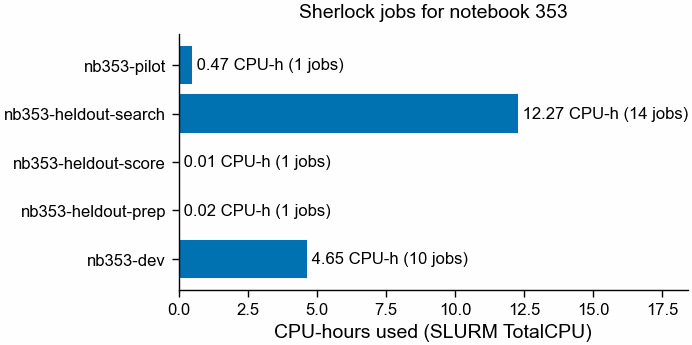

In [7]:
acct = pl.read_csv(RES / "sacct.tsv", separator="|", infer_schema_length=0)
# One row per job (array task); its TotalCPU already sums its steps (.batch, .extern).
acct = acct.filter(~pl.col("JobID").str.contains(r"\."))


def hms(s):
    s = s.strip()
    days = 0
    if "-" in s:
        d, s = s.split("-")
        days = int(d)
    parts = [float(x) for x in s.split(":")]
    while len(parts) < 3:
        parts.insert(0, 0.0)
    h, m, sec = parts
    return days * 24 + h + m / 60 + sec / 3600


acct = acct.with_columns(
    pl.col("TotalCPU").map_elements(hms, return_dtype=pl.Float64).alias("cpu_hours"),
    pl.col("Elapsed").map_elements(hms, return_dtype=pl.Float64).alias("elapsed_hours"),
)
print(
    acct.select(
        "JobID",
        "JobName",
        "State",
        "AllocCPUS",
        "Elapsed",
        "TotalCPU",
        "cpu_hours",
        "elapsed_hours",
        "Start",
        "End",
    )
)
start = min(acct["Start"])
end = max(acct["End"])
from datetime import datetime

span = (
    datetime.fromisoformat(end) - datetime.fromisoformat(start)
).total_seconds() / 3600
tot = (
    acct.group_by("JobName")
    .agg(
        pl.col("cpu_hours").sum(), pl.col("elapsed_hours").sum(), pl.len().alias("jobs")
    )
    .sort("JobName")
)
print(tot)
print(
    f"total CPU-hours {acct['cpu_hours'].sum():.2f}; summed job wall time {acct['elapsed_hours'].sum():.2f} h; first start to last end {span:.2f} h"
)
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 45)
ax.barh(tot["JobName"], tot["cpu_hours"], color=pf.OKABE_ITO["blue"])
for i, (c, n) in enumerate(zip(tot["cpu_hours"], tot["jobs"])):
    ax.text(c, i, f" {c:.2f} CPU-h ({n} jobs)", va="center", fontsize=6)
ax.set_xlabel("CPU-hours used (SLURM TotalCPU)")
ax.set_xlim(0, tot["cpu_hours"].max() * 1.5)
ax.set_title("Sherlock jobs for notebook 353", fontsize=7)
pf.save(fig, FIG / "353_cpu_hours_by_job")

## 8. Second reader's check: held and failed claims

A second agent that had not seen this work read the notebook, the scripts, the frozen data
and the kmerseek source at 0a22970, recomputed every number in the summary a second way from
the committed tables, and tried to disprove each claim (2026-10-20). Its list, and what was
changed in response:

| claim | verdict | what the reader found | change made |
|---|---|---|---|
| Rule written before any result | HELD | pre-registration 14:00:12; first job 14:09:46; `notebooks/353_prereg.md` unchanged since 641e7262 | none |
| Setting frozen before the held-out half ran | HELD | freeze commit 736d3f80 at 15:45:00; last development job ended 15:43:35; held-out prep started 15:47:13; later script changes are formatting only | none |
| Verdict "not run" follows the rule | HELD | the rule says so without the 100 real queries; `stage1/` holds only empty templates | none |
| Checksums in MANIFEST.tsv | HELD | all 6 match | none |
| Split by source protein | HELD | recomputed, 0 mismatches | none |
| Compute: 17.42 CPU-hours, 2.36 h first start to last end, 11.22 h summed | HELD | recomputed from sacct.tsv; the 13:54 start is not recorded in a file | none |
| mmseqs12 k = 4 picked | HELD | 0.8268, next best mmseqs12 k = 6 at 0.8215; none excluded (highest shuffle rate 0.037 vs cut 0.285) | none |
| 5,656 held-out records; 11,376 targets | PARTLY | 5,657 held-out records, one (4 residues) gives no window; the index holds 11,192 targets (184 skipped as repeated k-mer sets) | summary corrected |
| Point 1, within-class substitutions cost nothing | HELD | 0.9668 at every within-class level (15 aa); 30 aa unchanged is 0.9836, which rounds to 0.984; "cost what they cost any exact-word search" was never measured | 0.984 used; the comparison removed and marked as not measured |
| Point 2, found = placed | HELD | 0 differences in 203,616 queries at all four cut-offs; coordinates 0-based end-exclusive checked on every example row | none |
| Point 3, 4 of 22,624 found; self-match filter | HELD | `compare()` returns None when the two `md5sum` fields are equal, but that field is a sum of k-mer hashes, not an MD5; the 4 found are one record holding a U | wording corrected; U record named |
| Point 4, identical records | PARTLY | 92 is the E ≤ 10 count, 93 at E ≤ 0.1; the collapse is by k-mer set (329 records), and 92 of the 93 come from such records | rewritten with the k-mer-set count, both cut-offs, cells added in section 3 |
| Point 5, 0 of 18 strata calibrated; ratios | PARTLY | 0 of 18 and every ratio recomputed; the "thirds" are 5,417 / 4,089 / 7,462 windows because of ties | bin sizes stated and printed |
| Point 5, dipeptide excess lands on the window's own record | FAILED | in the 300-shuffle sample, of 45 regions at E ≤ 0.1: 12 own record, 28 other records of the same protein, 5 other proteins; pooled hit share 0.099 vs 0.095 predicted | sentence corrected to "records of the window's own protein"; sample split and hit share printed in section 4 |
| Point 6, 0.37 to 0.52 other-protein regions per query | PARTLY | right as a range over substitution levels; by length 0.08-0.24 (15), 0.35-0.48 (30), 0.69-0.84 (53); many are tile-to-tile | by-length values (0.16, 0.42, 0.77 pooled over levels) added; tiles of related factors named |
| Closing: 92 to 98% found with up to one cross-class change | HELD | 0.921 to 0.984 | none |

Other problems it raised:

1. The summary pointed to a second-reader section that did not exist yet: this is it.
2. `n_chunks` was fixed by hand on Sherlock and the repo did not say so: now stated in
   section 7.
3. All ten development settings lose the 53-residue, no-cross-class cells to the self-match
   filter, which lowers every score by the same cells; the choice stands.
4. The unit tests pass.
